In [ ]:
# ДЗ 6
# Реализовать преобразование Хаара (3 ступени сжатия).
# Исходное изображение: 512х512.

In [23]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

In [24]:
image = cv.imread('image6.jpg', cv.IMREAD_GRAYSCALE)
if image is None:
    image = np.random.randint(0, 256, (512, 512), dtype=np.uint8)
else:
    image = cv.resize(image, (512, 512))

In [25]:
def haar_2d(img, levels=3):
    c = img.astype(np.float32)
    for l in range(levels):
        n = c.shape[0] >> l
        b = c[:n, :n]
        b = np.hstack(((b[:, 0::2] + b[:, 1::2]) / 2.0, (b[:, 0::2] - b[:, 1::2]) / 2.0))
        c[:n, :n] = np.vstack(((b[0::2] + b[1::2]) / 2.0, (b[0::2] - b[1::2]) / 2.0))
    return c

In [26]:
def ihaar_2d(coef, levels=3):
    c = coef.copy()
    for l in range(levels - 1, -1, -1):
        n = c.shape[0] >> l
        k = n // 2
        b = c[:n, :n]
        t = np.empty_like(b)
        t[0::2], t[1::2] = b[:k] + b[k:], b[:k] - b[k:]
        c[:n, :n][:, 0::2], c[:n, :n][:, 1::2] = t[:, :k] + t[:, k:], t[:, :k] - t[:, k:]
    return c

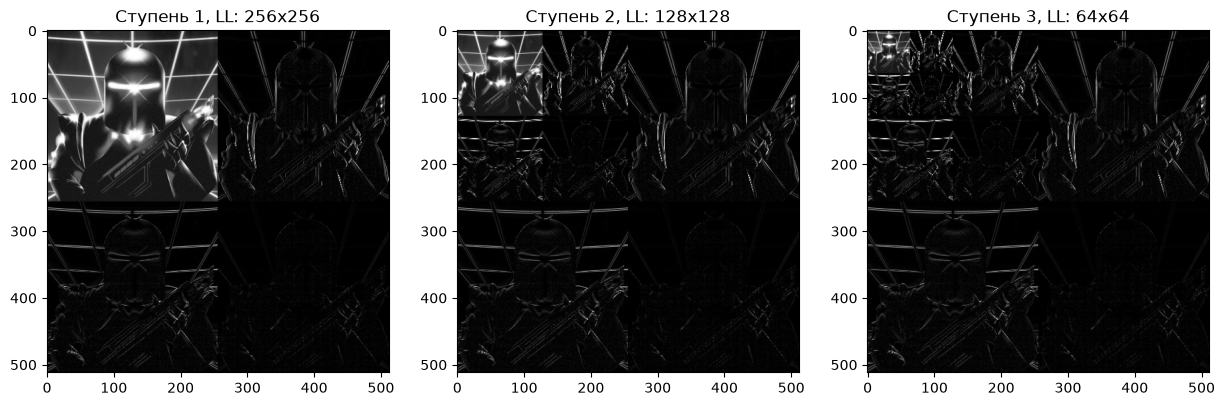

In [27]:
plt.figure(figsize=(15, 5))

for l in range(1, 4):
    coefs = haar_2d(image, levels=l)
    
    vis = np.abs(coefs)
    vis = np.clip(vis * 4, 0, 255)
    n = 512 >> l
    vis[:n, :n] = np.clip(coefs[:n, :n], 0, 255)
    
    plt.subplot(1, 3, l)
    plt.title(f'Ступень {l}, LL: {n}x{n}')
    plt.imshow(vis, cmap='gray')

plt.show()

Ступень 1: размер LL-блока = 256x256, сжатие в 4 раз(-а)
Ступень 2: размер LL-блока = 128x128, сжатие в 16 раз(-а)
Ступень 3: размер LL-блока = 64x64, сжатие в 64 раз(-а)


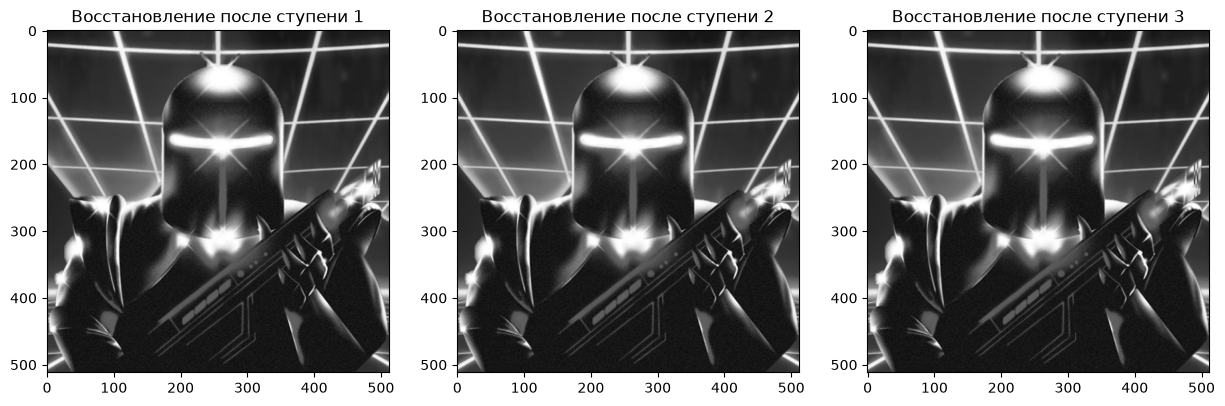

In [28]:
plt.figure(figsize=(15, 5))

for l in range(1, 4):
    coefs = haar_2d(image, levels=l)
    reconstructed = ihaar_2d(coefs, levels=l)
    
    plt.subplot(1, 3, l)
    plt.title(f'Восстановление после ступени {l}')
    plt.imshow(reconstructed, cmap='gray')
    
    print(f'Ступень {l}: размер LL-блока = {512 >> l}x{512 >> l}, сжатие в {(2**l)**2} раз(-а)')

plt.show()